# #216 causal p34 model-support panel

This notebook reads only the frozen outcome-unexposed package. `MEDIAN_KICKOFF_MINUS_10H` is the sole controlling readiness vote; the other #214 schedule epochs are sensitivity evidence only. Exact upstream cohorts remain distinct from the preregistered 30/5/2 chronological roles.

In [1]:
from pathlib import Path
from IPython.display import Image, display
import json
import pandas as pd
package = Path('results/bj216_model_support_panel_v1')
decision = json.loads((package / 'analysis/decision.json').read_text())
support = pd.read_csv(package / 'audit/issue_support.csv', dtype={'issue': str})
coverage = pd.read_csv(package / 'audit/coverage_by_role.csv')
sensitivity = pd.read_csv(package / 'audit/epoch_sensitivity.csv', dtype={'issue': str})
sensitivity_by_rule = pd.read_csv(package / 'audit/sensitivity_by_rule.csv')
curve = pd.read_csv(package / 'audit/time_ordered_coverage.csv', dtype={'issue': str})
panel = pd.read_parquet(package / 'inference/model_support_panel.parquet')
decision['disposition'], decision['model_ready_for_204'], len(panel)

('BLOCKED_ACCUMULATE_CAUSAL_SUPPORT', False, 5085)

In [2]:
coverage[['chronological_role', 'evaluated_issues', 'required_issues', 'core_match_coverage', 'n7_issue_pass_rate', 'role_gate_pass']]

,chronological_role,evaluated_issues,required_issues,core_match_coverage,n7_issue_pass_rate,role_gate_pass
0,development,24,30,0.786178,0.833333,False
1,chronological_evaluation,0,5,0.000000,0.000000,False
2,prospective_confirmation,0,2,0.000000,0.000000,False


In [3]:
sensitivity_by_rule[['epoch_rule', 'evaluated_issue_epochs', 'eligible_issue_epochs', 'core_match_coverage', 'n7_issue_pass_rate', 'controlling_readiness_vote', 'sensitivity_only']]

,epoch_rule,evaluated_issue_epochs,eligible_issue_epochs,core_match_coverage,n7_issue_pass_rate,controlling_readiness_vote,sensitivity_only
0,FIRST_KICKOFF_MINUS_10H,29,3,0.921569,1.000000,False,True
1,MEDIAN_KICKOFF_MINUS_10H,28,24,0.786178,0.833333,True,False
2,LAST_KICKOFF_MINUS_10H,28,28,0.761610,0.535714,False,True
3,FIRST_KICKOFF_MINUS_1H,29,3,1.000000,1.000000,False,True
4,MEDIAN_KICKOFF_MINUS_1H,28,24,0.754396,0.833333,False,True
5,LAST_KICKOFF_MINUS_1H,28,28,0.774194,0.035714,False,True


In [4]:
support.groupby(['upstream_cohort', 'chronological_role'], dropna=False).agg(issues=('issue', 'nunique'), candidates=('candidate_matches', 'sum'), core_complete=('core_complete_matches', 'sum')).reset_index()

,upstream_cohort,chronological_role,issues,candidates,core_complete
0,post_203_operational_observational,development,24,2156,1695
1,post_203_operational_observational,not_eligible,4,0,0
2,prospective_post_activation,not_eligible,1,0,0


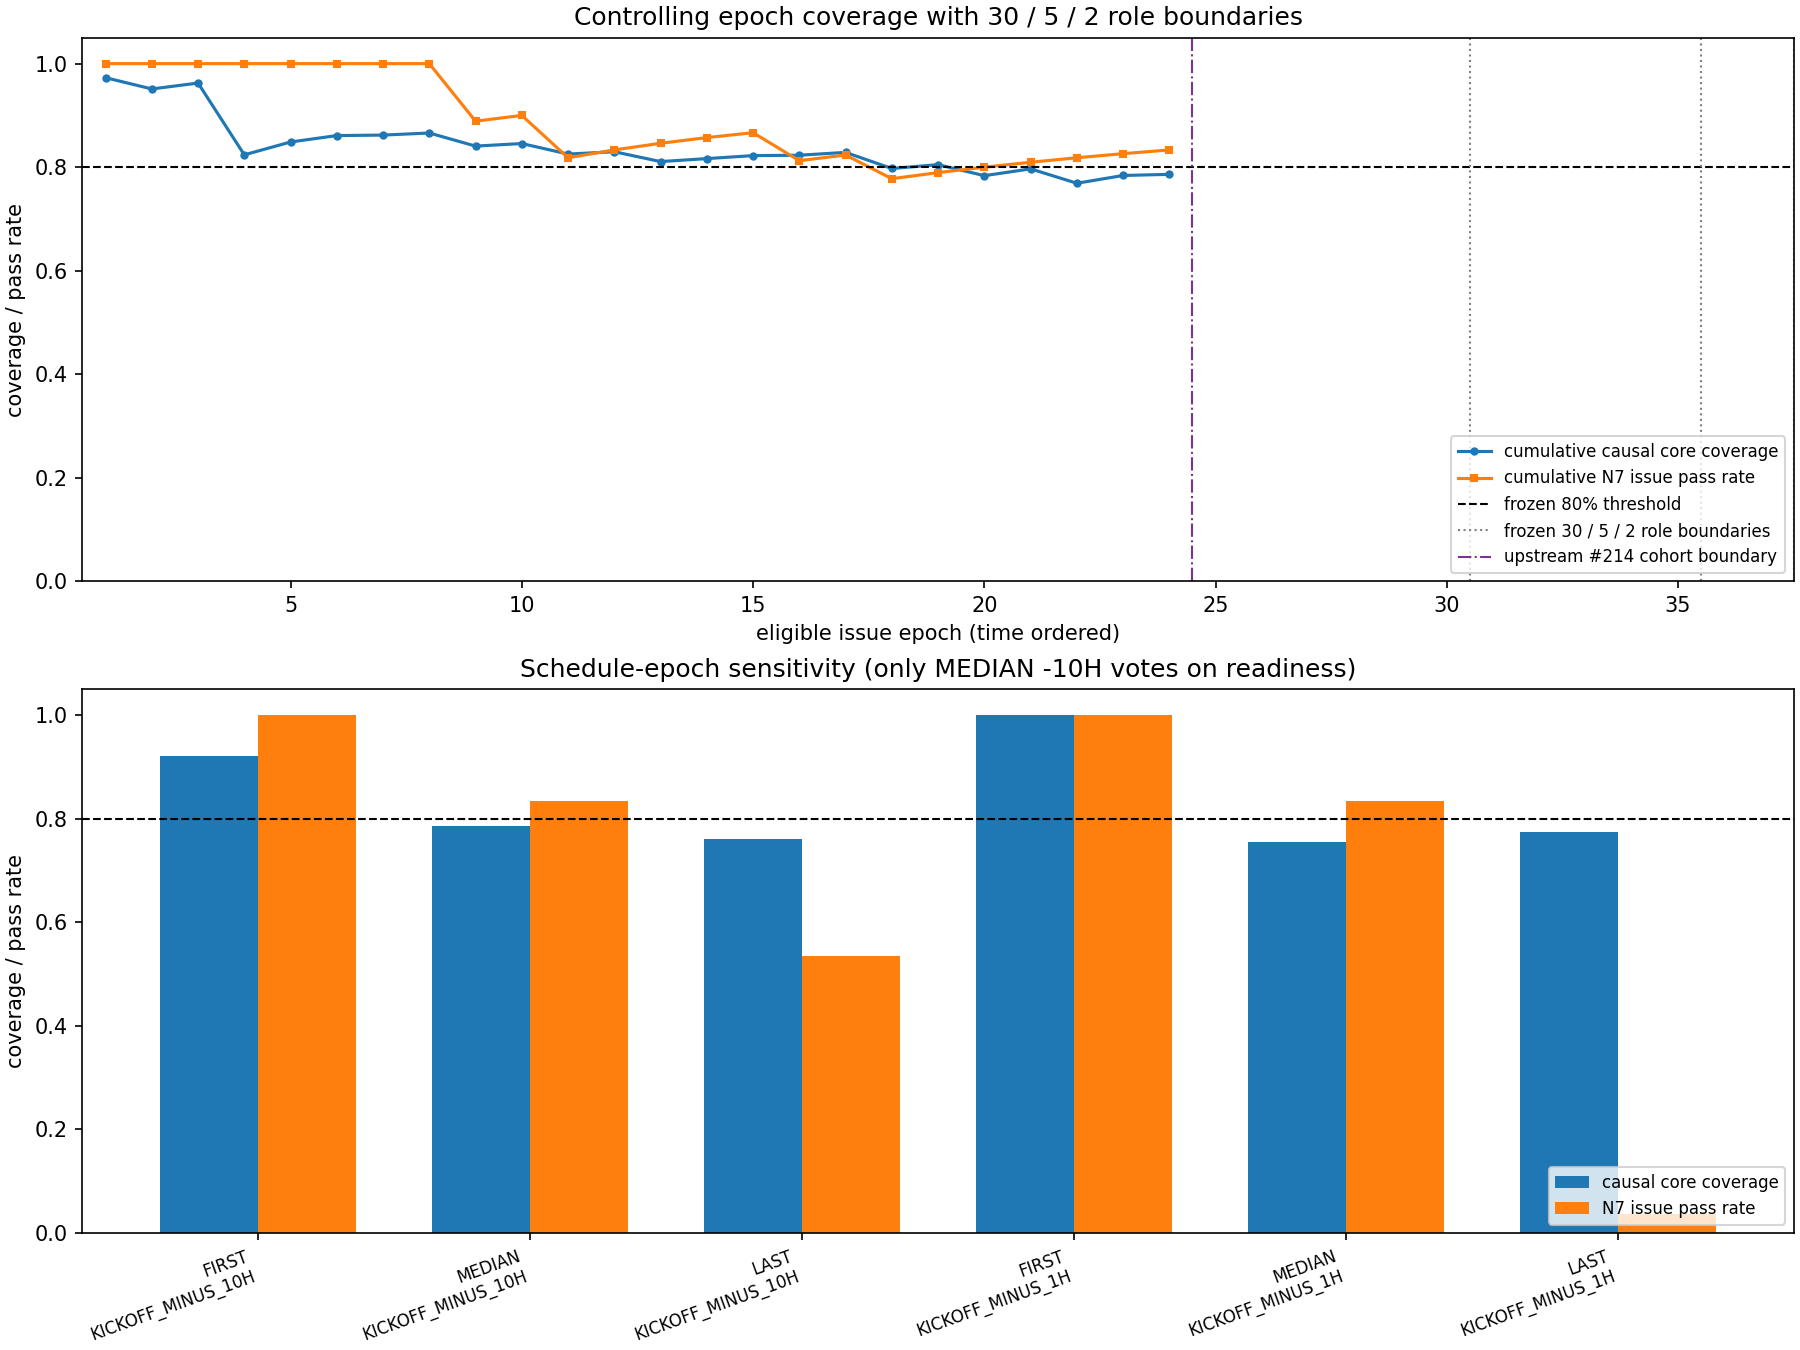

In [5]:
display(Image(filename=str(package / 'analysis/time_ordered_coverage.png')))

In [6]:
assert decision['outcome_namespace'] == 'PHYSICALLY_ABSENT'
assert decision['ticket_operability_metadata'] == 'NON_CONTROLLING_NOT_READ'
assert decision['epoch_sensitivity']['non_controlling_rules_do_not_vote'] is True
assert sensitivity.loc[sensitivity.controlling_readiness_vote, 'epoch_rule'].eq('MEDIAN_KICKOFF_MINUS_10H').all()
assert sensitivity.loc[~sensitivity.controlling_readiness_vote, 'sensitivity_only'].all()
assert set(support.upstream_cohort) == {'post_203_operational_observational', 'prospective_post_activation'}
assert not panel['panel_row_id'].duplicated().any()
assert (pd.to_datetime(panel.market_observed_ts_utc, utc=True) <= pd.to_datetime(panel.decision_epoch_utc, utc=True)).all()
decision['accumulation']

{'eligible_issue_epochs': 24,
 'issues_needed_before_development_horizon': 6,
 'issues_needed_before_full_readiness_horizon': 13,
 'next_measurable_condition': 'At least 37 chronologically assigned eligible issue epochs, with each required role meeting the frozen 80% N7 and 80% core coverage thresholds.'}

The frozen result remains negative until all preregistered support roles pass. Sensitivity epochs do not vote, this notebook does not fit a model, and the package grants no downstream execution authority.